# Academic Dropout Risk Analysis: Predictive Modeling

**Objective:** build a classification model that identifies students at risk of dropping out using only information assumed to be available after the first semester (Scenario A).

This notebook follows `01_eda.ipynb`, which describes the data and the associations with dropout.

# 1. Libraries

In [32]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict

# 2. Setup

In [33]:
df = pd.read_csv("../data/raw/student_dropout_risk_2026.csv")
print(f"Dataset shape: {df.shape}")

Dataset shape: (100000, 34)


# 3. Problem definition

- **Target:** `dropout` (1 = dropped out, 0 = stayed). About 32% of students dropped out.
- **Scenario A (early warning):** the model flags at-risk students using the information selected in section 4 as first-semester information.

# 4. Feature selection

**Scenario A (early-warning feature set).** The dataset description suggests an early-warning task using semester 1 features but does not define which variables belong to it, so the selection below is a design decision.

- **Not used as features:** `person_id` (identifier) and `dropout` (target).
- **Excluded because they are not first-semester information:** `gpa_semester_2` (measured after the second semester) and `semester`, `units_enrolled`, `units_passed`, `units_failed`, `missed_deadlines` (described as referring to the current semester; `units_passed` and `units_failed` are tied to `units_enrolled` by definition).
- **Included (26 features):** demographic, socioeconomic and institutional variables, admission and previous qualification grades, `gpa_semester_1`, and engagement and wellbeing variables.

**Assumption:** the dataset does not state the period covered by `attendance_rate`, `assignments_submitted_rate`, `library_visits_per_month`, `lms_logins_per_week`, `stress_level`, `satisfaction_score`, `tuition_up_to_date` and `mental_health_support`. They are assumed to be available after the first semester; this cannot be verified from the data.

A final comparison with all features will show how much the excluded variables add.

In [34]:
target = "dropout"
excluded = ["person_id", "gpa_semester_2", "semester",
            "units_enrolled", "units_passed", "units_failed", "missed_deadlines"]

features = [c for c in df.columns if c not in excluded + [target]]

# Split the selected features by type (needed to prepare the data)
cat_features = df[features].select_dtypes(exclude="number").columns.tolist()
num_features = df[features].select_dtypes(include="number").columns.tolist()

print("Number of features:", len(features))
print("Categorical:", cat_features)
print("Numeric:", num_features)

Number of features: 26
Categorical: ['gender', 'nationality', 'family_income_level', 'course_type', 'study_mode']
Numeric: ['age', 'first_generation', 'disability_status', 'scholarship_holder', 'tuition_up_to_date', 'part_time_job', 'weekly_work_hours', 'international_student', 'admission_grade', 'previous_qualification_grade', 'gpa_semester_1', 'attendance_rate', 'assignments_submitted_rate', 'library_visits_per_month', 'lms_logins_per_week', 'extracurricular_activities', 'stress_level', 'mental_health_support', 'satisfaction_score', 'commute_time_mins', 'sleep_hours']


# 5. Train / Test split

The data are split into 80% training and 20% test sets, stratified by `dropout` so both keep the same dropout rate (about 32%). The test set is not used until the final evaluation. Preprocessing (scaling and encoding) will be fitted on the training set only, inside a pipeline, to avoid information leakage from the test set.

In [35]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Dropout rate - train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

Train: (80000, 26) | Test: (20000, 26)
Dropout rate - train: 0.32 | test: 0.32


# 6. Baseline model: Logistic Regression

A logistic regression is used as a baseline. Numeric features are standardized and categorical features are one-hot encoded inside a pipeline, so the preprocessing is fitted only on the training folds. The model is evaluated with 5-fold stratified cross-validation on the training set (the test set is kept for the final evaluation) using ROC-AUC and PR-AUC. A random model would score 0.5 in ROC-AUC and about 0.32 in PR-AUC (the dropout rate).

In [36]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

logreg = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(logreg, X_train, y_train, cv=cv,
                        scoring=["roc_auc", "average_precision"])

for metric in ["roc_auc", "average_precision"]:
    s = scores[f"test_{metric}"]
    print(f"{metric}: {s.mean():.3f} (+/- {s.std():.3f})")

roc_auc: 0.896 (+/- 0.001)
average_precision: 0.817 (+/- 0.001)


**Baseline results (5-fold stratified cross-validation on the training set):** ROC-AUC 0.896 (±0.001) and PR-AUC 0.817 (±0.001). Both are well above the random-model values (0.5 and about 0.32) and are stable across folds.

The Kaggle description lists a logistic regression ROC-AUC of about 0.79, but it does not state which features or validation scheme were used, so the values are not directly comparable. The dataset description states that `dropout` was generated with a logistic model, which is consistent with a linear model performing well here; this has not been verified.

# 7. Gradient Boosting

A histogram-based gradient boosting model is evaluated with the same cross-validation and metrics to check whether non-linear relationships or interactions add predictive value over the logistic baseline. Trees do not need scaled features, so only the categorical variables are one-hot encoded.

In [37]:
preprocessor_gb = ColumnTransformer([
    ("num", "passthrough", num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])

gboost = Pipeline([
    ("preprocess", preprocessor_gb),
    ("model", HistGradientBoostingClassifier(random_state=42)),
])

scores_gb = cross_validate(gboost, X_train, y_train, cv=cv,
                           scoring=["roc_auc", "average_precision"])

for metric in ["roc_auc", "average_precision"]:
    s = scores_gb[f"test_{metric}"]
    print(f"{metric}: {s.mean():.3f} (+/- {s.std():.3f})")

roc_auc: 0.893 (+/- 0.002)
average_precision: 0.812 (+/- 0.001)


**Gradient boosting results (5-fold stratified cross-validation on the training set):** ROC-AUC 0.893 (±0.002) and PR-AUC 0.812 (±0.001), slightly below the logistic baseline (0.896 and 0.817). With default hyperparameters, gradient boosting does not improve on the baseline, so no evidence was found that non-linear effects or interactions add predictive value for these features. The logistic regression is kept as the model for Scenario A because it performs at least as well and is easier to interpret. Hyperparameters were not tuned.

# 8. Comparison with all features

To estimate how much the variables excluded from Scenario A add, the logistic regression is evaluated again using all 32 features (everything except `person_id` and `dropout`), with the same cross-validation folds and metrics. This comparison is made on the training set only.

In [38]:
features_all = [c for c in df.columns if c not in ["person_id", target]]
cat_all = df[features_all].select_dtypes(exclude="number").columns.tolist()
num_all = df[features_all].select_dtypes(include="number").columns.tolist()
print("Number of features:", len(features_all))

preprocessor_all = ColumnTransformer([
    ("num", StandardScaler(), num_all),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_all),
])

logreg_all = Pipeline([
    ("preprocess", preprocessor_all),
    ("model", LogisticRegression(max_iter=1000)),
])

# Same training rows as before, now with all features
X_train_all = df.loc[X_train.index, features_all]

scores_all = cross_validate(logreg_all, X_train_all, y_train, cv=cv,
                            scoring=["roc_auc", "average_precision"])

for metric in ["roc_auc", "average_precision"]:
    s = scores_all[f"test_{metric}"]
    print(f"{metric}: {s.mean():.3f} (+/- {s.std():.3f})")

Number of features: 32
roc_auc: 0.904 (+/- 0.002)
average_precision: 0.831 (+/- 0.002)


**Results (5-fold stratified cross-validation on the training set):** with all 32 features the logistic regression reaches ROC-AUC 0.904 (±0.002) and PR-AUC 0.831 (±0.002), compared with 0.896 and 0.817 for the 26 Scenario A features. The excluded variables add about 0.008 in ROC-AUC and 0.014 in PR-AUC, a small gain that is larger than the fold-to-fold variation. Restricting the model to Scenario A features therefore costs little predictive performance in this dataset. A possible reason is the overlap among academic variables observed in the EDA (e.g., r = 0.83 between the two GPAs), but this was not tested. Since the data are synthetic and the timing of the variables is not documented, this should not be read as a statement about real early-warning systems.

# 9. Final evaluation on the test set

The selected model (logistic regression with the 26 Scenario A features) is fitted on the full training set and evaluated once on the test set. Precision, recall and F1 are reported at the default threshold of 0.5.

Test ROC-AUC: 0.896
Test PR-AUC:  0.818

              precision    recall  f1-score   support

      Stayed      0.855     0.907     0.880     13599
 Dropped out      0.774     0.674     0.720      6401

    accuracy                          0.833     20000
   macro avg      0.814     0.790     0.800     20000
weighted avg      0.829     0.833     0.829     20000



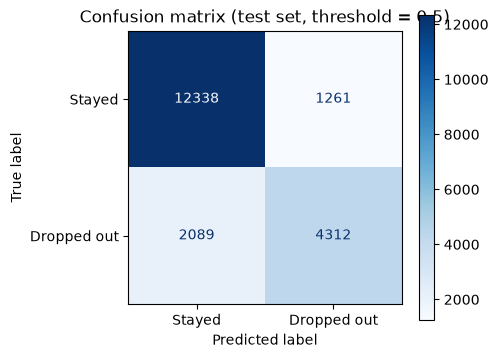

In [39]:
logreg.fit(X_train, y_train)

proba = logreg.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"Test ROC-AUC: {roc_auc_score(y_test, proba):.3f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, proba):.3f}")
print()
print(classification_report(y_test, pred, target_names=["Stayed", "Dropped out"], digits=3))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Dropped out"],
                                        cmap="Blues", ax=ax)
ax.set_title("Confusion matrix (test set, threshold = 0.5)")
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrix.png", dpi=150)
plt.show()

**Test set results:** ROC-AUC 0.896 and PR-AUC 0.818, in line with the cross-validation results (0.896 and 0.817). At the default threshold of 0.5 accuracy is 0.833 (a model that always predicts "stayed" would reach 0.68).

For the dropout class, precision is 0.774 and recall is 0.674: the model identifies 4,312 of the 6,401 students who dropped out (67.4%), and 77.4% of the students it flags actually dropped out. It misses 2,089 dropouts and raises 1,261 false alarms (about 9% of the students who stayed).

The threshold of 0.5 is the default and not a choice based on the goal of an early-warning system; it is revisited next.

# 10. Decision threshold

The decision threshold is studied using out-of-fold predicted probabilities on the training set, so the test set stays untouched. For each threshold the table shows precision, recall and F1 for the dropout class and the percentage of students flagged as at risk.

In [40]:
# Out-of-fold probabilities on the training set (no test data used)
proba_oof = cross_val_predict(logreg, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.2, 0.65, 0.05):
    pred_t = (proba_oof >= t).astype(int)
    tp = ((pred_t == 1) & (y_train == 1)).sum()
    fp = ((pred_t == 1) & (y_train == 0)).sum()
    fn = ((pred_t == 0) & (y_train == 1)).sum()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    rows.append({
        "threshold": round(t, 2),
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall),
        "flagged_%": pred_t.mean() * 100,
    })

pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1,flagged_%
0,0.20,0.581,0.899,0.706,49.486
1,0.25,0.618,0.866,0.721,44.878
2,0.30,0.652,0.831,0.731,40.749
3,0.35,0.684,0.796,0.736,37.231
4,0.40,0.715,0.759,0.736,33.978
5,0.45,0.743,0.719,0.731,30.974
6,0.50,0.769,0.678,0.721,28.231
7,0.55,0.795,0.634,0.706,25.539
8,0.60,0.819,0.590,0.686,23.034


**Results (out-of-fold predictions on the training set):** at the default threshold of 0.5, precision is 0.769 and recall 0.678. F1 is highest at thresholds 0.35 and 0.40 (0.736) and varies little between 0.30 and 0.45 (0.731 to 0.736), so F1 alone does not determine the choice. Lowering the threshold increases recall at the cost of precision and flags more students: at 0.30 recall is 0.831, precision 0.652 and 40.7% of students are flagged; at 0.45 recall is 0.719, precision 0.743 and 31.0% are flagged.

The appropriate threshold depends on the relative cost of missing a dropout versus raising a false alarm, which cannot be determined from the data.

**Chosen threshold: 0.30**, based on the criterion of detecting at least 80% of the students who drop out. In the out-of-fold predictions, 0.30 gives recall 0.831 (0.35 gives 0.796, just below the target), precision 0.652, and flags 40.7% of students. The threshold was chosen using the training set only and is applied once to the test set in the next section.

# 11. Test set evaluation at the chosen threshold

The chosen threshold (0.30) is applied once to the test set. The result is reported as it is: the threshold is not adjusted based on the test set.

Threshold: 0.3
Flagged as at risk: 40.4% of test students

              precision    recall  f1-score   support

      Stayed      0.908     0.796     0.849     13599
 Dropped out      0.657     0.830     0.733      6401

    accuracy                          0.807     20000
   macro avg      0.783     0.813     0.791     20000
weighted avg      0.828     0.807     0.812     20000



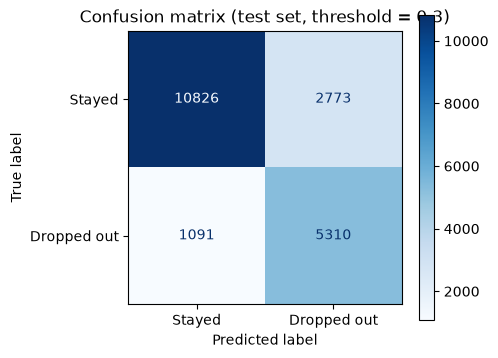

In [41]:
threshold = 0.30
pred_test = (proba >= threshold).astype(int)

print(f"Threshold: {threshold}")
print(f"Flagged as at risk: {pred_test.mean() * 100:.1f}% of test students")
print()
print(classification_report(y_test, pred_test, target_names=["Stayed", "Dropped out"], digits=3))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["Stayed", "Dropped out"],
                                        cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix (test set, threshold = {threshold})")
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrix_threshold_030.png", dpi=150)
plt.show()

**Test set results at threshold 0.30:** the model flags 40.4% of test students as at risk. It identifies 5,310 of the 6,401 students who dropped out (recall 0.830), above the 80% target and in line with the cross-validation estimate (0.831). Precision is 0.657: roughly two out of three flagged students dropped out. It misses 1,091 dropouts and raises 2,773 false alarms (about 20% of the students who stayed). Accuracy is 0.807, lower than at threshold 0.5 (0.833), which is expected when the threshold is lowered to favor recall.

These results are on synthetic data, so they illustrate the methodology and should not be read as expected performance in a real institution.

# 12. Model interpretation

The coefficients of the logistic regression fitted on the full training set are used to see which features are most associated with dropout. Numeric features were standardized, so each coefficient is the change in the log-odds of dropping out per one standard deviation, and the exponential of the coefficient is the corresponding odds ratio. Coefficients describe associations conditional on the other features and do not imply causation. For categorical features, only differences between categories of the same variable are meaningful, so they are shown separately.

                              coefficient  odds_ratio_per_SD
gpa_semester_1                     -1.660              0.190
attendance_rate                    -0.416              0.660
tuition_up_to_date                 -0.369              0.692
weekly_work_hours                   0.334              1.396
lms_logins_per_week                -0.307              0.736
assignments_submitted_rate         -0.273              0.761
stress_level                        0.260              1.297
scholarship_holder                 -0.221              0.802
library_visits_per_month           -0.213              0.808
first_generation                    0.159              1.173
satisfaction_score                 -0.142              0.868
extracurricular_activities         -0.133              0.875
admission_grade                    -0.095              0.910
part_time_job                      -0.051              0.951
sleep_hours                        -0.049              0.953
disability_status       

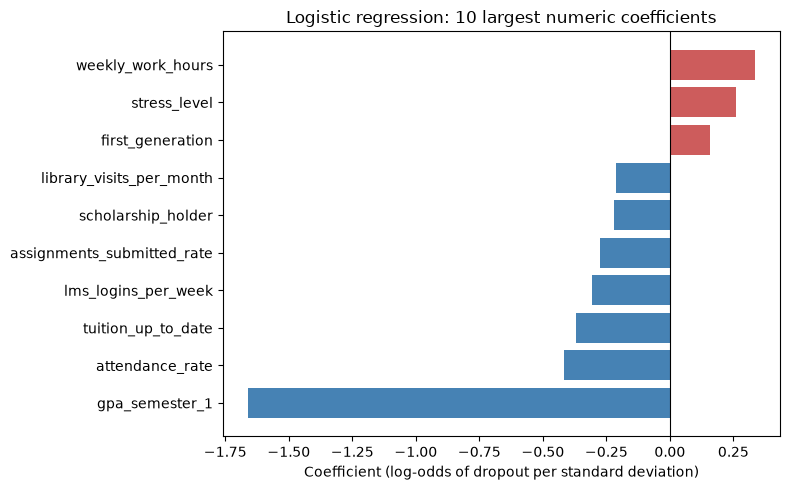

In [42]:
feature_names = logreg.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=feature_names)
coefs.index = [name.split("__", 1)[1] for name in coefs.index]

# Numeric features: coefficient and odds ratio per one standard deviation
num_coefs = coefs[num_features].sort_values(key=abs, ascending=False)
print(pd.DataFrame({"coefficient": num_coefs, "odds_ratio_per_SD": np.exp(num_coefs)}).round(3))

# Check the relation between the two work variables
print("\nCorrelation part_time_job vs weekly_work_hours:",
      round(df["part_time_job"].corr(df["weekly_work_hours"]), 2))

# Plot: 10 numeric features with the largest absolute coefficient
plot_data = num_coefs.head(10).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(plot_data.index, plot_data.values,
         color=np.where(plot_data.values > 0, "indianred", "steelblue"))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic regression: 10 largest numeric coefficients")
plt.xlabel("Coefficient (log-odds of dropout per standard deviation)")
plt.tight_layout()
plt.savefig("../reports/figures/logreg_coefficients.png", dpi=150)
plt.show()

**Numeric features (coefficient and odds ratio per one standard deviation, conditional on the other features):**

- `gpa_semester_1` is by far the strongest: one standard deviation more (about 0.79 GPA points) is associated with odds of dropout multiplied by about 0.19, all else equal.
- Next come `attendance_rate` (OR 0.66), `tuition_up_to_date` (0.69), `weekly_work_hours` (1.40), `lms_logins_per_week` (0.74), `assignments_submitted_rate` (0.76) and `stress_level` (1.30). Higher attendance, LMS activity, assignment submission and up-to-date tuition go with lower risk; more weekly work hours and higher stress go with higher risk.
- Smaller associations: `scholarship_holder` (0.80), `library_visits_per_month` (0.81) and `first_generation` (1.17). For binary variables "per standard deviation" is less intuitive, so mainly the sign and relative size should be read.
- `part_time_job` has almost no coefficient (-0.05) although it showed a gap in the EDA, because it is strongly correlated with `weekly_work_hours` (0.89), which captures most of its information. Their separate coefficients should not be interpreted individually.
- Practically no association once the other features are included: `age`, `international_student`, `mental_health_support`, `previous_qualification_grade`, `commute_time_mins`, `sleep_hours` and `disability_status` (|coefficient| < 0.05).

In [43]:
# Categorical features: only differences between categories of the same variable are meaningful
for var in cat_features:
    c = coefs[[n for n in coefs.index if n.startswith(var + "_")]]
    print(f"\n{var}: spread (max - min) = {c.max() - c.min():.3f}")
    print(c.round(3).to_string())


gender: spread (max - min) = 0.119
gender_Female   -0.231
gender_Male     -0.247
gender_Other    -0.127

nationality: spread (max - min) = 0.201
nationality_Australia     -0.084
nationality_Brazil        -0.020
nationality_Canada        -0.150
nationality_China         -0.013
nationality_Egypt          0.002
nationality_Germany        0.051
nationality_India         -0.012
nationality_Indonesia     -0.039
nationality_Mexico        -0.104
nationality_Nigeria       -0.023
nationality_Pakistan      -0.015
nationality_Philippines   -0.027
nationality_South Korea   -0.093
nationality_UK            -0.019
nationality_USA           -0.058

family_income_level: spread (max - min) = 0.813
family_income_level_High     -0.599
family_income_level_Low       0.215
family_income_level_Middle   -0.221

course_type: spread (max - min) = 0.057
course_type_Arts & Humanities       -0.089
course_type_Business                -0.122
course_type_Health Sciences         -0.137
course_type_Law & Social Science

**Categorical features:** only differences between categories of the same variable are meaningful.

- `family_income_level` shows the largest difference: the coefficients are +0.22 (Low), -0.22 (Middle) and -0.60 (High), a spread of 0.81. Holding the other features constant, the odds of dropout for low-income students are about 2.3 times those of high-income students (exp(0.81)) and about 1.5 times those of middle-income students.
- The other categorical features show much smaller differences between categories: `nationality` (0.20 across 15 countries), `gender` (0.12), `course_type` (0.06) and `study_mode` (0.03). In the EDA, differences by gender, nationality and course type were also small; the gap by study mode seen there (Online 29.2% vs. Part-time 33.7%) almost disappears once the other features are included.
- The negative sign of most individual categorical coefficients is an artifact of how categories are encoded and is not interpreted.

**Summary:** the coefficients tell the same story as the EDA. Semester-1 GPA is the dominant factor, followed by attendance, financial variables (tuition status, family income, weekly work hours) and engagement and stress indicators. Most demographic and institutional variables add little (`first_generation` is a modest exception). These are conditional associations in synthetic data and do not imply causal effects.

# 13. Fairness check across groups

Model performance is compared across family income levels, gender and first-generation status on the test set, using the chosen threshold (0.30). For each group the table shows its size, actual dropout rate, share of students flagged, recall (share of actual dropouts detected), false alarm rate (share of students who stayed that are flagged) and precision. Groups with a higher dropout rate are expected to be flagged more often; the comparison focuses on whether recall and false alarm rates are similar across groups. This is a descriptive check: neither the model nor the threshold is adjusted based on it.

In [44]:
eval_df = X_test[["family_income_level", "gender", "first_generation"]].copy()
eval_df["y"] = y_test
eval_df["flagged"] = pred_test

def group_metrics(g):
    tp = ((g["flagged"] == 1) & (g["y"] == 1)).sum()
    fp = ((g["flagged"] == 1) & (g["y"] == 0)).sum()
    return pd.Series({
        "n": len(g),
        "dropout_rate_%": g["y"].mean() * 100,
        "flagged_%": g["flagged"].mean() * 100,
        "recall": tp / (g["y"] == 1).sum(),
        "false_alarm_rate": fp / (g["y"] == 0).sum(),
        "precision": tp / (tp + fp),
    })

for var in ["family_income_level", "gender", "first_generation"]:
    print(f"\n{var}")
    print(eval_df.groupby(var)[["y", "flagged"]].apply(group_metrics).round(3))


family_income_level
                          n  dropout_rate_%  flagged_%  recall  \
family_income_level                                              
High                 4975.0          19.819     24.161   0.726   
Low                  6932.0          42.859     55.323   0.878   
Middle               8093.0          30.199     37.637   0.812   

                     false_alarm_rate  precision  
family_income_level                               
High                            0.122      0.596  
Low                             0.309      0.681  
Middle                          0.188      0.651  

gender
              n  dropout_rate_%  flagged_%  recall  false_alarm_rate  \
gender                                                                 
Female  10117.0          31.620     40.219   0.827             0.206   
Male     9530.0          32.403     40.672   0.833             0.203   
Other     353.0          32.295     39.093   0.807             0.192   

        precision  
gend

**Results (test set, threshold 0.30):**

- **Family income:** recall is 0.878 for low-income students, 0.812 for middle-income and 0.726 for high-income students. The false alarm rate (0.309, 0.188 and 0.122) and the share flagged (55.3%, 37.6% and 24.2%) show the same ordering, and the latter follows the actual dropout rates (42.9%, 30.2% and 19.8%). Precision varies less (0.681, 0.651 and 0.596). With a single threshold, low-income students are flagged more often, both correctly (more dropouts detected) and incorrectly (more false alarms), while dropouts among high-income students are missed more often (27.4% missed vs. 12.2% for low-income students).
- **First-generation status:** first-generation students are flagged more often (47.4% vs. 35.4%), with higher recall (0.859 vs. 0.802) and a higher false alarm rate (0.245 vs. 0.178), the same pattern as income; their actual dropout rate is also higher (37.3% vs. 28.2%).
- **Gender:** results are very similar for female and male students (recall 0.827 and 0.833, false alarm rate 0.206 and 0.203). The "Other" group has only 353 students (about 114 dropouts), so its figures are too noisy to compare reliably.

Groups with a higher dropout rate are flagged more often and show both higher recall and higher false alarm rates. At a single threshold the model does not behave equally across income and first-generation groups, while no noticeable difference appears by gender. Whether these gaps come from the model using these variables or from differences in dropout rates between groups was not tested. Results are descriptive and based on synthetic data.

# 14. Conclusions

1. **Model (Scenario A):** a logistic regression with 26 first-semester-style features reaches ROC-AUC 0.896 and PR-AUC 0.818 on the test set. Gradient boosting did not improve on it, and adding the 6 excluded features gave only a small gain (+0.008 ROC-AUC in cross-validation).
2. **Threshold:** at 0.30, chosen to detect at least 80% of dropouts, the model detects 83.0% of dropouts with a precision of 65.7% and flags 40.4% of students.
3. **Main factors:** semester-1 GPA dominates, followed by attendance, tuition status, weekly work hours, LMS activity, assignment submission and stress, with a clear gradient by family income. These are conditional associations, not causal effects.
4. **Group comparison:** performance is similar by gender, but at a single threshold low-income and first-generation students are flagged more often, with higher recall and higher false alarm rates.
5. **Limitations:** the data are synthetic, `dropout` has no date and most variables do not specify their period, so "early warning" is a design choice that cannot be verified, and the results illustrate the methodology rather than real-world performance.